# **1. Import Required Libraries**

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV

# **2. Load Dataset**

In [2]:
# Load the dataset
df = pd.read_csv('/content/Loan_default.csv')
print(df.shape)
df.head()

(255347, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


# **3. Dataset Information**

In [3]:
# Display dataset shape, columns and structure
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()

Dataset Shape: (255347, 18)

Column Names:
['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education    

# **4. Statistical Summary**

In [4]:
# Summary statistics for numerical variables
df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


# **5. Missing Values Check**

In [5]:
# Check missing values in each column
missing_values = df.isnull().sum()
print("Missing Values in Each Column:")
print(missing_values)
print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:
LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

Total Missing Values: 0


# **6. Duplicate Records Check**

In [6]:
# Check for completely duplicated rows
duplicate_rows = df.duplicated().sum()
print("Number of Duplicate Rows:", duplicate_rows)

Number of Duplicate Rows: 0


# **7. Unique LoanID Check**

In [7]:
# Check LoanID uniqueness
unique_loan_ids = df['LoanID'].nunique()
duplicate_loan_ids = df['LoanID'].duplicated().sum()
print("Total Records:", len(df))
print("Unique LoanIDs:", unique_loan_ids)
print("Duplicate LoanIDs:", duplicate_loan_ids)

Total Records: 255347
Unique LoanIDs: 255347
Duplicate LoanIDs: 0


# **8. Identify Numerical, Categorical and Target Variables**

In [8]:
# Classify numerical, categorical and target variables
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
numerical_features.remove('Default')
categorical_features = df.select_dtypes(include=['object']).columns.tolist()
categorical_features.remove('LoanID')
target_variable = 'Default'
print("Numerical Features:")
print(numerical_features)
print("\nCategorical Features:")
print(categorical_features)
print("\nTarget Variable:")
print(target_variable)

Numerical Features:
['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']

Categorical Features:
['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']

Target Variable:
Default


# **9. Check Unique Values in Categorical Variables**

In [9]:
# Display unique values and categories for each categorical variable
for column in categorical_features:
    print(f"\n{column}")
    print("Number of Unique Values:", df[column].nunique())
    print("Categories:", df[column].unique())


Education
Number of Unique Values: 4
Categories: ["Bachelor's" "Master's" 'High School' 'PhD']

EmploymentType
Number of Unique Values: 4
Categories: ['Full-time' 'Unemployed' 'Self-employed' 'Part-time']

MaritalStatus
Number of Unique Values: 3
Categories: ['Divorced' 'Married' 'Single']

HasMortgage
Number of Unique Values: 2
Categories: ['Yes' 'No']

HasDependents
Number of Unique Values: 2
Categories: ['Yes' 'No']

LoanPurpose
Number of Unique Values: 5
Categories: ['Other' 'Auto' 'Business' 'Home' 'Education']

HasCoSigner
Number of Unique Values: 2
Categories: ['Yes' 'No']


# **10. Target Variable Distribution**

In [10]:
# Count and percentage of each Default category
default_counts = df['Default'].value_counts().sort_index()
print("Default Counts:")
print(default_counts)
default_percentages = df['Default'].value_counts(normalize=True).sort_index() * 100
print("\nDefault Percentages:")
print(default_percentages.round(2))

Default Counts:
Default
0    225694
1     29653
Name: count, dtype: int64

Default Percentages:
Default
0    88.39
1    11.61
Name: proportion, dtype: float64


# **11. Target Distribution Visualisation**

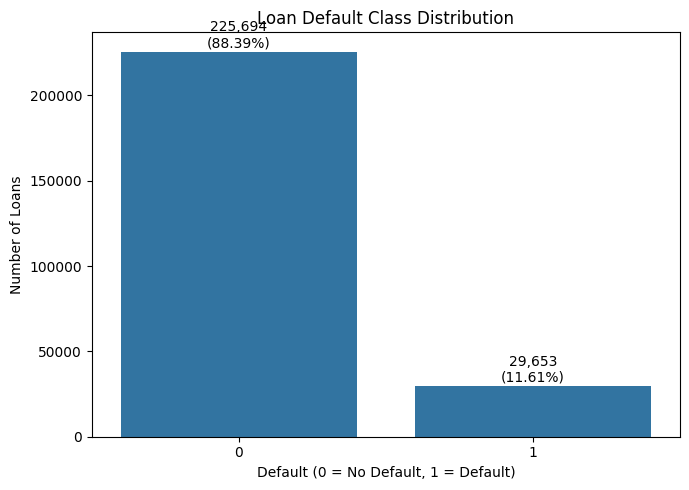

In [11]:
# Visualise the target class distribution
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='Default')
total = len(df)
for i, count in enumerate(default_counts):
    percentage = (count / total) * 100
    ax.text(i, count + (total * 0.01), f'{count:,}\n({percentage:.2f}%)', ha='center')
plt.title('Loan Default Class Distribution')
plt.xlabel('Default (0 = No Default, 1 = Default)')
plt.ylabel('Number of Loans')
plt.tight_layout()
plt.show()

# **12. Numerical Variables - Range and Unique Value Check**

In [12]:
# Validate the range and uniqueness of numerical variables
numerical_validation = pd.DataFrame({
    'Data Type': df[numerical_features].dtypes,
    'Unique Values': df[numerical_features].nunique(),
    'Minimum': df[numerical_features].min(),
    'Maximum': df[numerical_features].max()
})
display(numerical_validation)

,Data Type,Unique Values,Minimum,Maximum
Age,int64,52,18.0,69.0
Income,int64,114620,15000.0,149999.0
LoanAmount,int64,158729,5000.0,249999.0
CreditScore,int64,550,300.0,849.0
MonthsEmployed,int64,120,0.0,119.0
NumCreditLines,int64,4,1.0,4.0
InterestRate,float64,2301,2.0,25.0
LoanTerm,int64,5,12.0,60.0
DTIRatio,float64,81,0.1,0.9


# **13. Categorical Variables - Frequency Check**

In [13]:
# Validate the frequency distribution of each categorical variable
for column in categorical_features:
    print(f"\n{'=' * 50}")
    print(f"{column}")
    print(f"{'=' * 50}")
    print(df[column].value_counts())


Education
Education
Bachelor's     64366
High School    63903
Master's       63541
PhD            63537
Name: count, dtype: int64

EmploymentType
EmploymentType
Part-time        64161
Unemployed       63824
Self-employed    63706
Full-time        63656
Name: count, dtype: int64

MaritalStatus
MaritalStatus
Married     85302
Divorced    85033
Single      85012
Name: count, dtype: int64

HasMortgage
HasMortgage
Yes    127677
No     127670
Name: count, dtype: int64

HasDependents
HasDependents
Yes    127742
No     127605
Name: count, dtype: int64

LoanPurpose
LoanPurpose
Business     51298
Home         51286
Education    51005
Other        50914
Auto         50844
Name: count, dtype: int64

HasCoSigner
HasCoSigner
Yes    127701
No     127646
Name: count, dtype: int64


# **14. Target Variable Validation**

In [14]:
# Validate the target variable values
print("Unique values in Default:")
print(sorted(df['Default'].unique()))
print("\nNumber of unique target values:")
print(df['Default'].nunique())

Unique values in Default:
[np.int64(0), np.int64(1)]

Number of unique target values:
2


# **15. Exploratory Data Analysis**

# **15. Distribution of Numerical Variables**

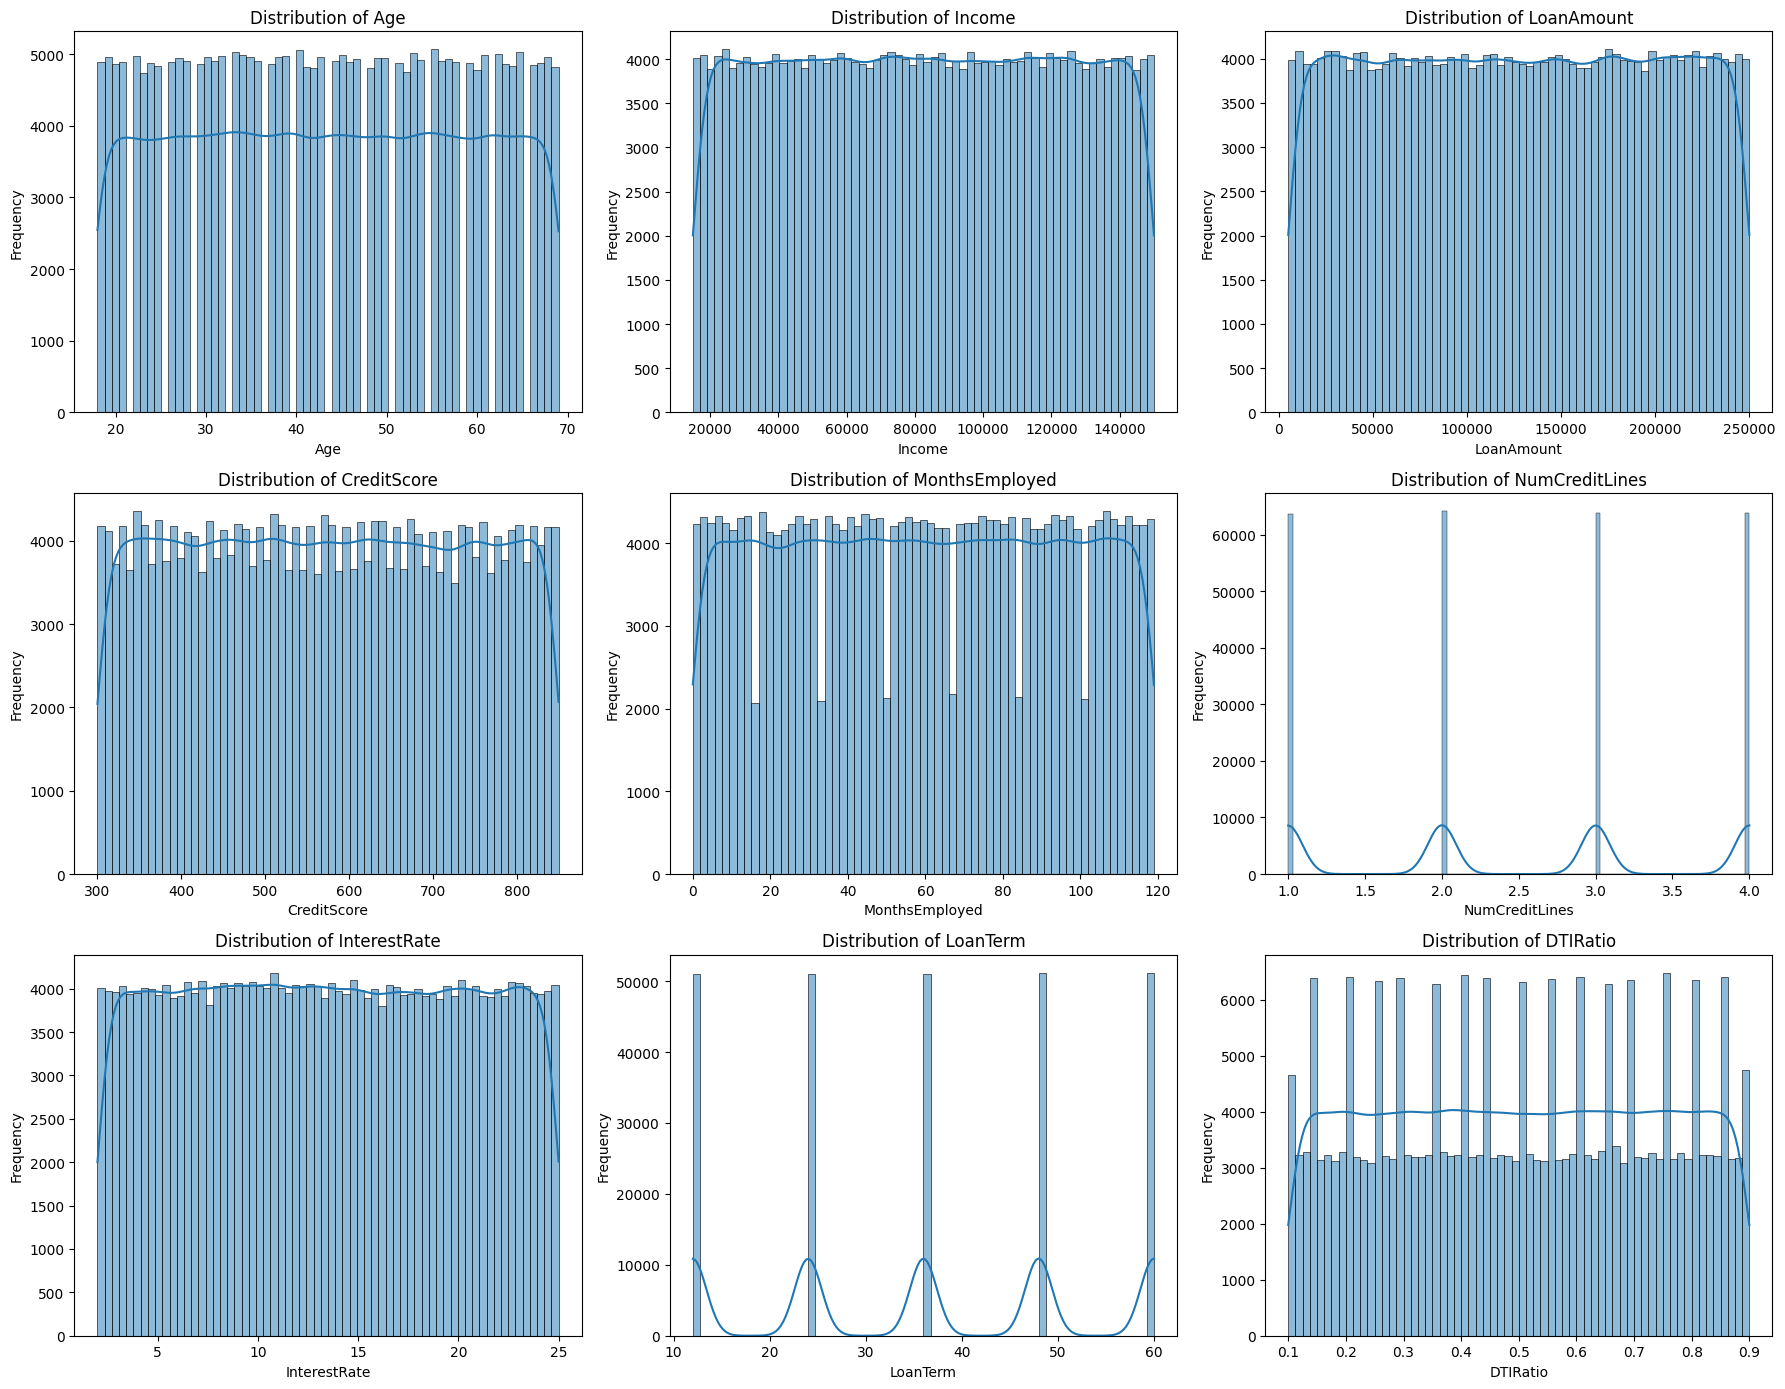

In [15]:
# Plot the distribution of numerical variables
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, column in zip(axes.flatten(), numerical_features):
    sns.histplot(data=df, x=column, kde=True, ax=ax)
    ax.set_title(f'Distribution of {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

# **16. Numerical Variables by Default Status**

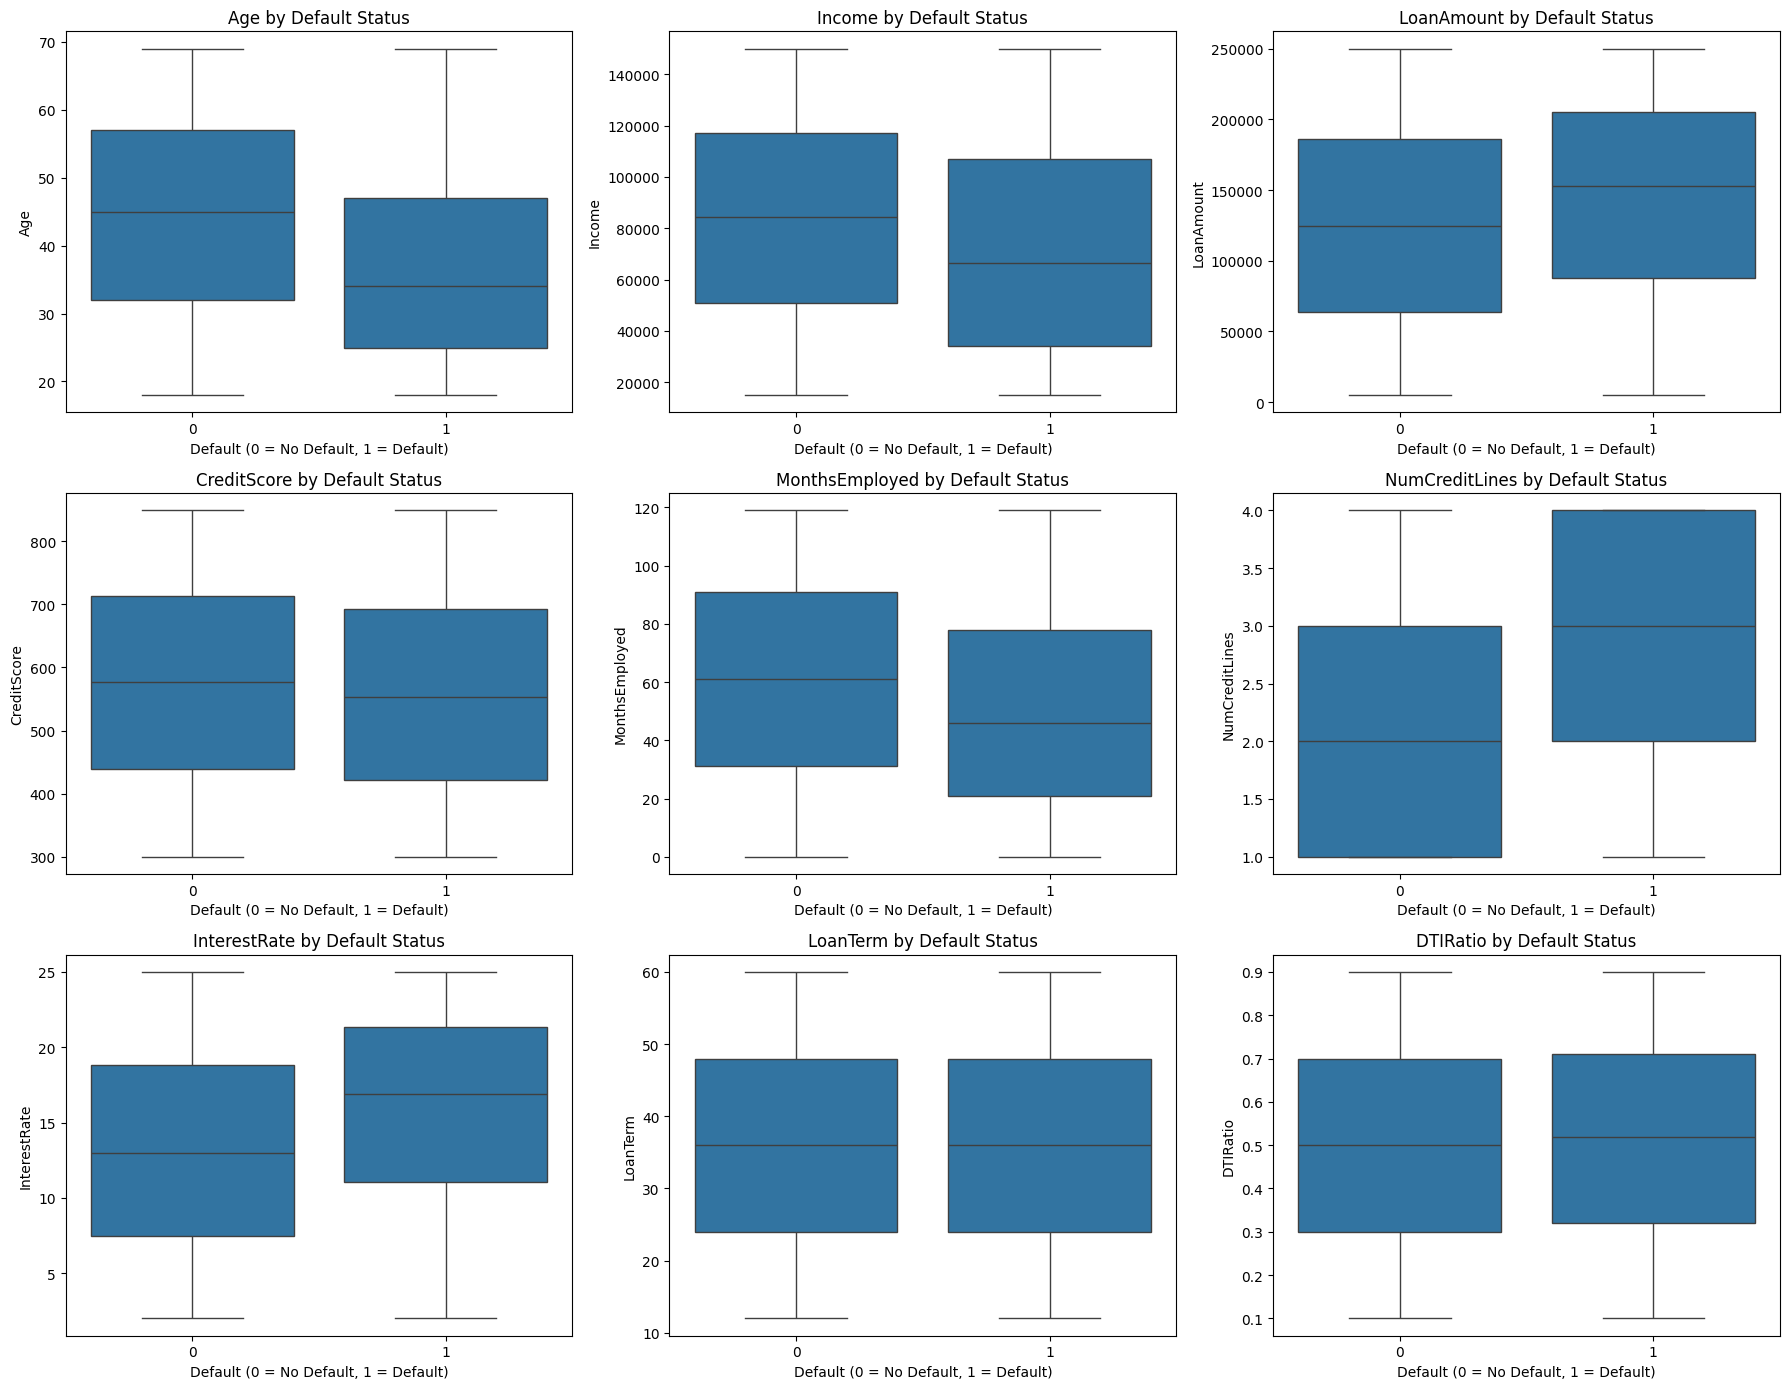

In [16]:
# Compare numerical variables by default status
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, column in zip(axes.flatten(), numerical_features):
    sns.boxplot(data=df, x='Default', y=column, ax=ax)
    ax.set_title(f'{column} by Default Status')
    ax.set_xlabel('Default (0 = No Default, 1 = Default)')
    ax.set_ylabel(column)
plt.tight_layout()
plt.show()

# **17. Default Rate by Categorical Variables**

In [17]:
# Calculate the default rate for each categorical variable
for column in categorical_features:
    default_rate = df.groupby(column)['Default'].mean().mul(100).sort_values(ascending=False).round(2)
    print(f"\n{column} - Default Rate (%)")
    display(default_rate.to_frame(name='Default Rate (%)'))


Education - Default Rate (%)


,Default Rate (%)
Education,
High School,12.88
Bachelor's,12.10
Master's,10.87
PhD,10.59



EmploymentType - Default Rate (%)


,Default Rate (%)
EmploymentType,
Unemployed,13.55
Part-time,11.97
Self-employed,11.46
Full-time,9.46



MaritalStatus - Default Rate (%)


,Default Rate (%)
MaritalStatus,
Divorced,12.53
Single,11.91
Married,10.40


... (4 outputs left out)


LoanPurpose - Default Rate (%)


,Default Rate (%)
LoanPurpose,
Business,12.33
Auto,11.88
Education,11.84
Other,11.79
Home,10.23



HasCoSigner - Default Rate (%)


,Default Rate (%)
HasCoSigner,
No,12.87
Yes,10.36


# **18. Visualisation of Default Rates**

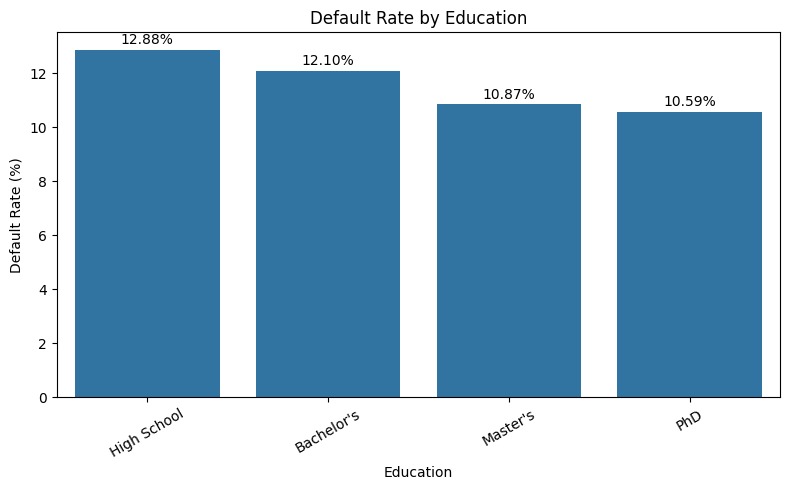

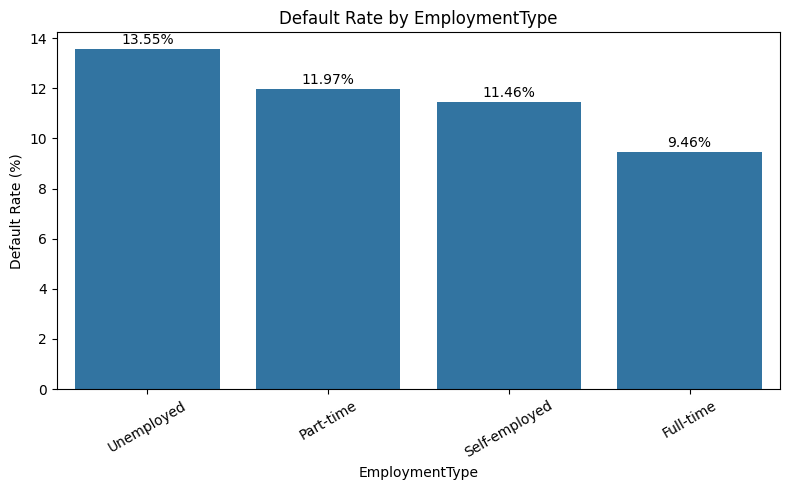

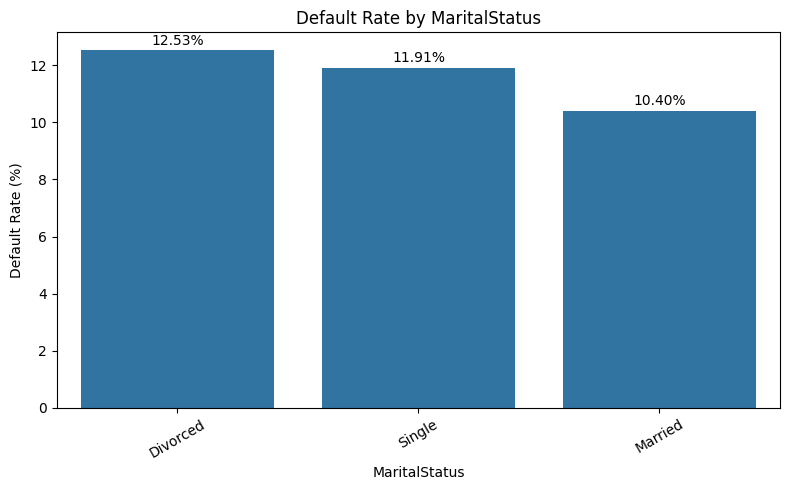

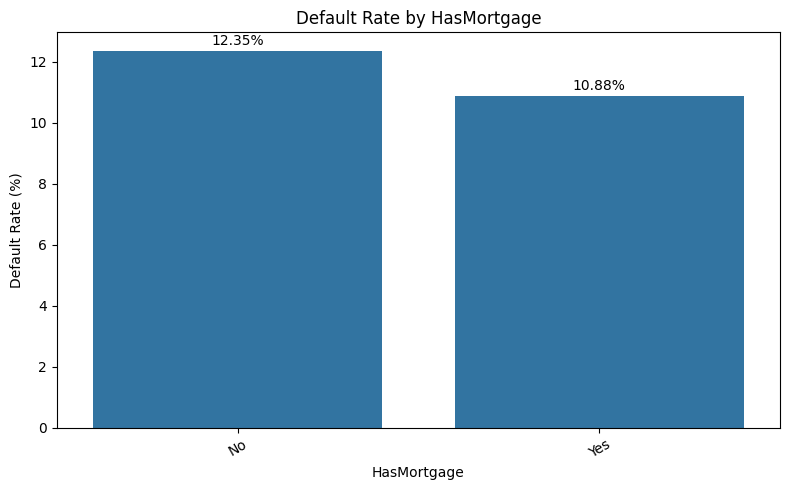

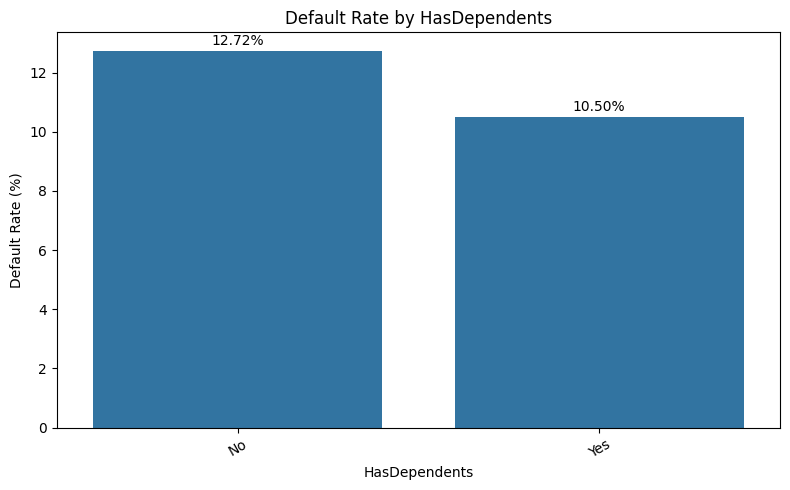

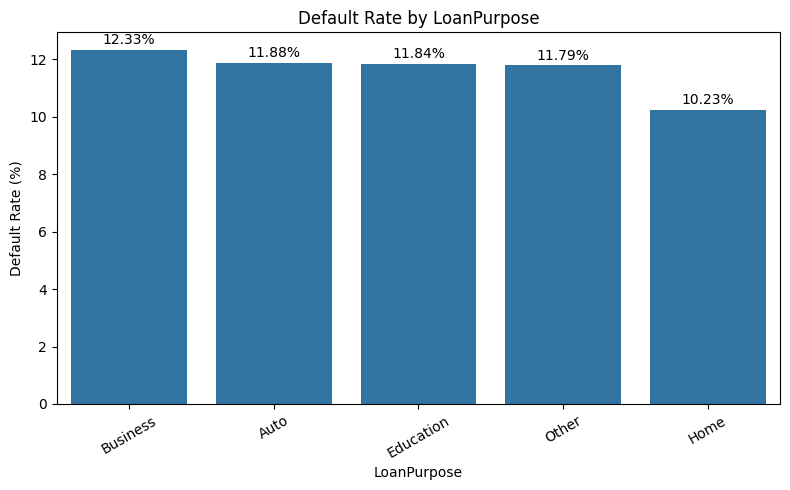

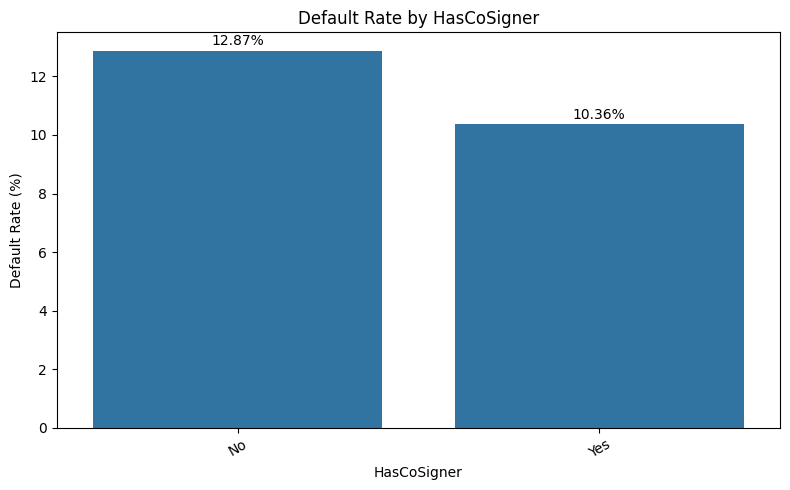

In [18]:
# Plot the default rate by each categorical variable
for column in categorical_features:
    default_rate = df.groupby(column)['Default'].mean().mul(100).sort_values(ascending=False)
    plt.figure(figsize=(8, 5))
    ax = sns.barplot(x=default_rate.index, y=default_rate.values)
    for i, value in enumerate(default_rate.values):
        ax.text(i, value + 0.2, f'{value:.2f}%', ha='center')
    plt.title(f'Default Rate by {column}')
    plt.xlabel(column)
    plt.ylabel('Default Rate (%)')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# **19. Correlation Analysis**

In [19]:
# Calculate correlation of numerical variables with Default
correlation_matrix = df[numerical_features + ['Default']].corr()
default_correlation = correlation_matrix['Default'].drop('Default').sort_values(ascending=False)
print("Correlation of Numerical Variables with Default:")
display(default_correlation.to_frame(name='Correlation with Default'))

Correlation of Numerical Variables with Default:


,Correlation with Default
InterestRate,0.131273
LoanAmount,0.086659
NumCreditLines,0.028330
DTIRatio,0.019236
LoanTerm,0.000545
CreditScore,-0.034166
MonthsEmployed,-0.097374
Income,-0.099119
Age,-0.167783


# **20. Correlation Heatmap**

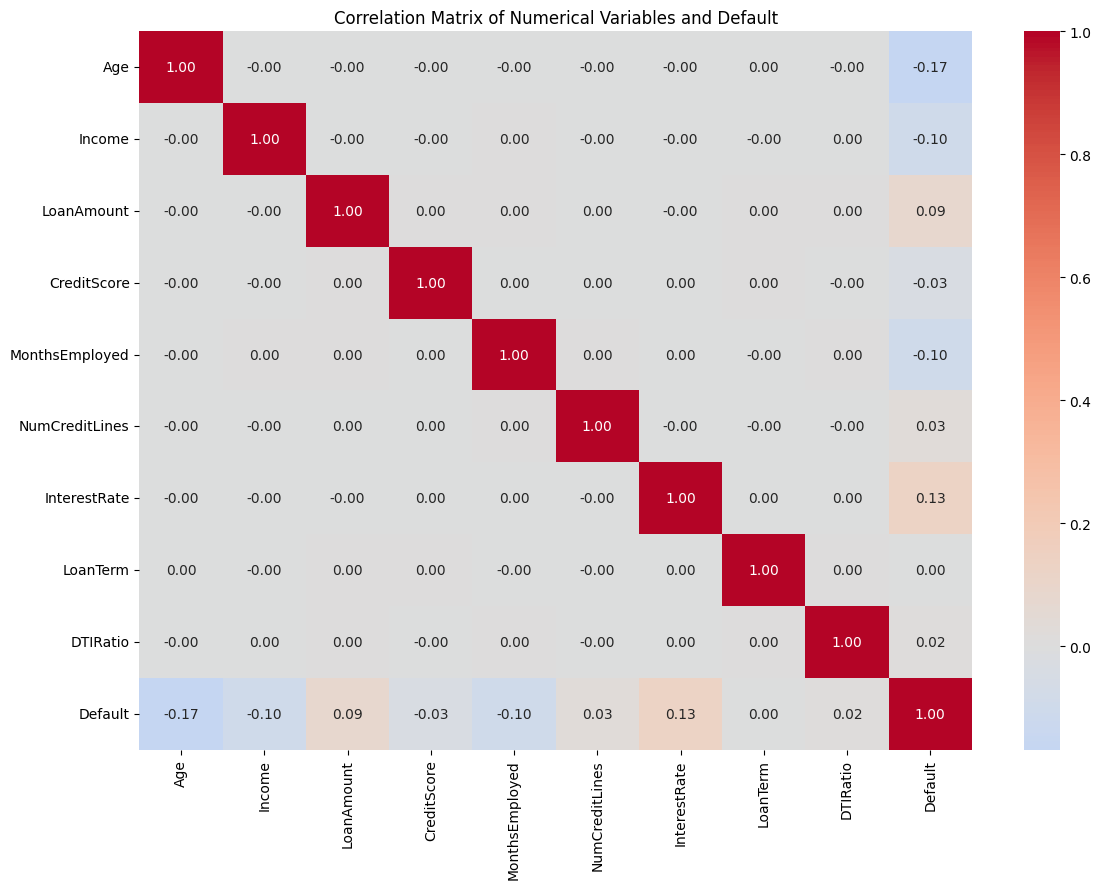

In [20]:
# Plot the correlation heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Numerical Variables and Default')
plt.tight_layout()
plt.show()

# **21. Outlier Detection Using IQR**

In [21]:
# Detect outliers in numerical variables using the IQR method
outlier_summary = []
for column in numerical_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = ((df[column] < lower_bound) | (df[column] > upper_bound)).sum()
    percentage = (outliers / len(df)) * 100
    outlier_summary.append([column, Q1, Q3, lower_bound, upper_bound, outliers, percentage])
outlier_summary = pd.DataFrame(outlier_summary, columns=['Variable', 'Q1', 'Q3', 'Lower Bound', 'Upper Bound', 'Outlier Count', 'Outlier Percentage'])
outlier_summary['Outlier Percentage'] = outlier_summary['Outlier Percentage'].round(2)
display(outlier_summary)

,Variable,Q1,Q3,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Age,31.00,56.00,-6.50,93.50,0,0.0
1,Income,48825.50,116219.00,-52264.75,217309.25,0,0.0
2,LoanAmount,66156.00,188985.00,-118087.50,373228.50,0,0.0
3,CreditScore,437.00,712.00,24.50,1124.50,0,0.0
4,MonthsEmployed,30.00,90.00,-60.00,180.00,0,0.0
5,NumCreditLines,2.00,3.00,0.50,4.50,0,0.0
6,InterestRate,7.77,19.25,-9.45,36.47,0,0.0
7,LoanTerm,24.00,48.00,-12.00,84.00,0,0.0
8,DTIRatio,0.30,0.70,-0.30,1.30,0,0.0


# **22. Outlier Treatment Decision**

No numerical variable is capped, winsorised or removed based on the IQR flags above. In a credit-risk
context, borrowers at the extremes of income, loan amount, interest rate or DTI are often exactly the
high-risk cases the model needs to learn from, so removing them would discard genuine signal rather than
noise. All flagged values are retained, and tree-based models (Decision Tree, Random Forest, XGBoost,
LightGBM) used later in this notebook are not sensitive to outliers in the way linear models can be.

# **23. Numerical Variables vs Default Correlation**

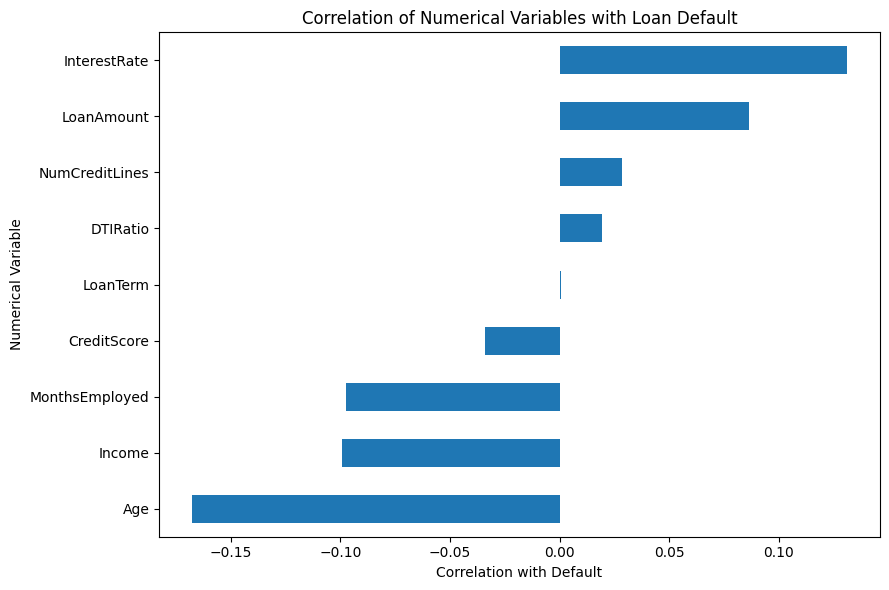

In [22]:
# Plot correlation of numerical variables with default
plt.figure(figsize=(9, 6))
default_correlation.sort_values().plot(kind='barh')
plt.title('Correlation of Numerical Variables with Loan Default')
plt.xlabel('Correlation with Default')
plt.ylabel('Numerical Variable')
plt.tight_layout()
plt.show()

# **25. Feature Engineering**

# **24. Create Loan-to-Income Ratio**

In [23]:
# Engineer the Loan-to-Income ratio feature
df['LoanToIncomeRatio'] = df['LoanAmount'] / df['Income']
print("LoanToIncomeRatio created successfully.")
display(df[['Income', 'LoanAmount', 'LoanToIncomeRatio']].head())

LoanToIncomeRatio created successfully.


,Income,LoanAmount,LoanToIncomeRatio
0,85994,50587,0.588262
1,50432,124440,2.467481
2,84208,129188,1.534154
3,31713,44799,1.412638
4,20437,9139,0.447179


# **25. Check the New Feature**

In [24]:
# Summarise the new Loan-to-Income ratio feature
print("LoanToIncomeRatio Summary:")
display(df['LoanToIncomeRatio'].describe())
print("\nLoanToIncomeRatio by Default Status:")
display(df.groupby('Default')['LoanToIncomeRatio'].agg(['mean', 'median', 'std']).round(3))

LoanToIncomeRatio Summary:


,LoanToIncomeRatio
count,255347.000000
mean,2.177480
std,2.178357
min,0.033749
25%,0.803628
50%,1.546720
75%,2.671744
max,16.532460



LoanToIncomeRatio by Default Status:


,mean,median,std
Default,,,
0,2.036,1.496,1.973
1,3.253,2.050,3.152


# **26. Compare Loan-to-Income Ratio by Default**

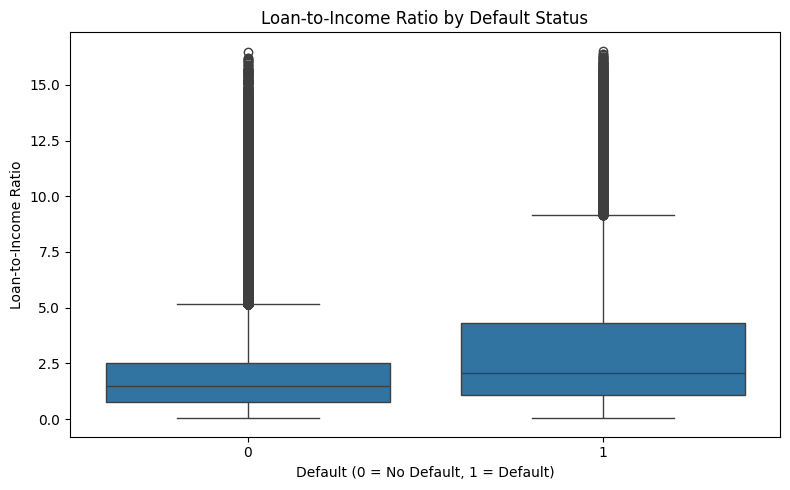

In [25]:
# Compare the Loan-to-Income ratio by default status
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Default', y='LoanToIncomeRatio')
plt.title('Loan-to-Income Ratio by Default Status')
plt.xlabel('Default (0 = No Default, 1 = Default)')
plt.ylabel('Loan-to-Income Ratio')
plt.tight_layout()
plt.show()

# **27. Define Features and Target**

In [26]:
# Define the feature matrix and target vector
X = df.drop(columns=['LoanID', 'Default'])
y = df['Default']
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (255347, 17)
Target Shape: (255347,)


# **28. Stratified Train-Test Split**

In [27]:
# Perform a stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Training Set:", X_train.shape)
print("Testing Set:", X_test.shape)
print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))
print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training Set: (204277, 17)
Testing Set: (51070, 17)

Training Target Distribution:
Default
0    88.39
1    11.61
Name: proportion, dtype: float64

Testing Target Distribution:
Default
0    88.39
1    11.61
Name: proportion, dtype: float64


# **29. Create Preprocessing Pipeline**

In [28]:
# Build the preprocessing pipeline (LoanTerm and NumCreditLines are kept as numeric since their values are ordered and their spacing is meaningful)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_features = ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'LoanToIncomeRatio']
categorical_features = ['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']

numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])
print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


# **30. Fit Preprocessing on Training Data**

In [29]:
# Fit the preprocessor on training data and transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Processed Training Shape: (204277, 32)
Processed Testing Shape: (51070, 32)


# **31. Logistic Regression - Baseline Model**

In [30]:
# Train the baseline Logistic Regression model
from sklearn.linear_model import LogisticRegression
logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_train_processed, y_train)
print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


# **32. Logistic Regression - Predictions and Evaluation**

In [31]:
# Evaluate the baseline Logistic Regression model
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve, precision_recall_curve, auc

y_pred_lr = logistic_model.predict(X_test_processed)
y_prob_lr = logistic_model.predict_proba(X_test_processed)[:, 1]

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression Performance")
print("--------------------------------")
print(f"Accuracy : {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall   : {lr_recall:.4f}")
print(f"F1-Score : {lr_f1:.4f}")
print(f"ROC-AUC  : {lr_roc_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Performance
--------------------------------
Accuracy : 0.8869
Precision: 0.6146
Recall   : 0.0696
F1-Score : 0.1251
ROC-AUC  : 0.7617

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.99      0.94     45139
           1       0.61      0.07      0.13      5931

    accuracy                           0.89     51070
   macro avg       0.75      0.53      0.53     51070
weighted avg       0.86      0.89      0.84     51070



# **33. Logistic Regression - Confusion Matrix**

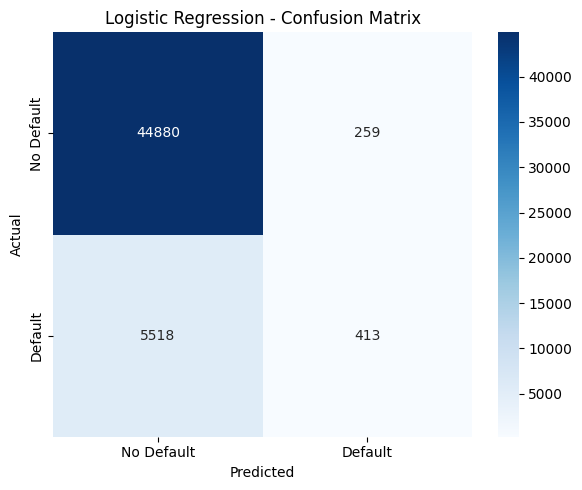

In [32]:
# Plot the confusion matrix for Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# **34. Decision Tree - Baseline Model**

In [33]:
# Train the baseline Decision Tree model
from sklearn.tree import DecisionTreeClassifier
decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(X_train_processed, y_train)
print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


# **35. Decision Tree - Evaluation**

In [34]:
# Evaluate the baseline Decision Tree model
y_pred_dt = decision_tree.predict(X_test_processed)
y_prob_dt = decision_tree.predict_proba(X_test_processed)[:, 1]

dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)
dt_roc_auc = roc_auc_score(y_test, y_prob_dt)

print("Decision Tree Performance")
print("-------------------------")
print(f"Accuracy : {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1-Score : {dt_f1:.4f}")
print(f"ROC-AUC  : {dt_roc_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Performance
-------------------------
Accuracy : 0.8017
Precision: 0.1979
Recall   : 0.2318
F1-Score : 0.2135
ROC-AUC  : 0.5542

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.88      0.89     45139
           1       0.20      0.23      0.21      5931

    accuracy                           0.80     51070
   macro avg       0.55      0.55      0.55     51070
weighted avg       0.82      0.80      0.81     51070



# **36. Decision Tree - Confusion Matrix**

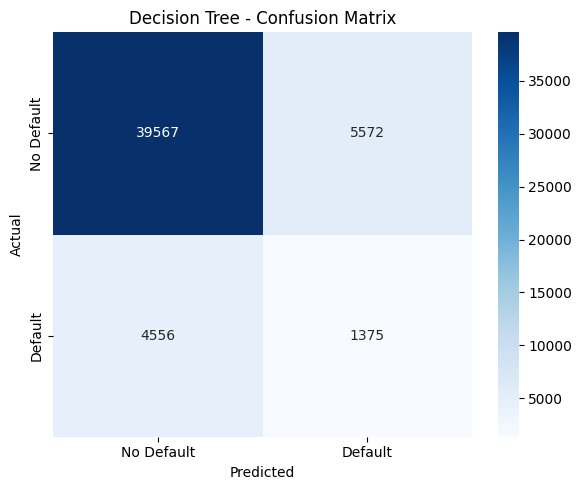

In [35]:
# Plot the confusion matrix for the Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# **37. Baseline Model Comparison**

In [36]:
# Compare baseline model performance
baseline_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [lr_accuracy, dt_accuracy],
    'Precision': [lr_precision, dt_precision],
    'Recall': [lr_recall, dt_recall],
    'F1-Score': [lr_f1, dt_f1],
    'ROC-AUC': [lr_roc_auc, dt_roc_auc]
})
display(baseline_results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8869,0.6146,0.0696,0.1251,0.7617
1,Decision Tree,0.8017,0.1979,0.2318,0.2135,0.5542


# **38. ROC Curve Comparison**

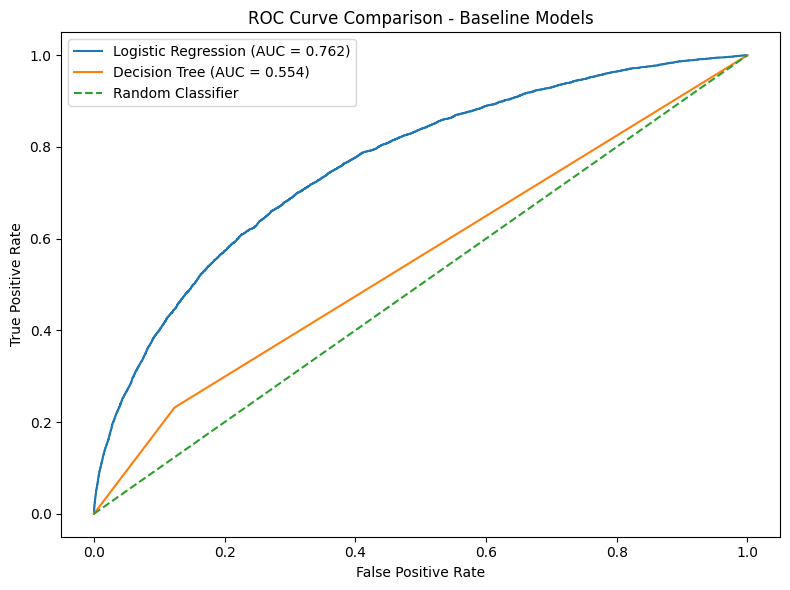

In [37]:
# Compare ROC curves for the baseline models
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)

plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {lr_roc_auc:.3f})')
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {dt_roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.title('ROC Curve Comparison - Baseline Models')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.tight_layout()
plt.show()

# **39. Apply SMOTE to Training Data**

In [38]:
# Apply SMOTE to balance the training data
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_processed, y_train)
print("Original Training Distribution:")
print(y_train.value_counts())
print("\nSMOTE Training Distribution:")
print(y_train_smote.value_counts())

Original Training Distribution:
Default
0    180555
1     23722
Name: count, dtype: int64

SMOTE Training Distribution:
Default
0    180555
1    180555
Name: count, dtype: int64


# **40. Verify Class Balance**

In [39]:
# Verify the class balance before and after SMOTE
print("Before SMOTE:")
print(y_train.value_counts(normalize=True).mul(100).round(2))
print("\nAfter SMOTE:")
print(y_train_smote.value_counts(normalize=True).mul(100).round(2))

Before SMOTE:
Default
0    88.39
1    11.61
Name: proportion, dtype: float64

After SMOTE:
Default
0    50.0
1    50.0
Name: proportion, dtype: float64


# **41. Logistic Regression with SMOTE**

In [40]:
# Train Logistic Regression on the SMOTE-balanced data
logistic_smote = LogisticRegression(max_iter=1000, random_state=42)
logistic_smote.fit(X_train_smote, y_train_smote)

y_pred_lr_smote = logistic_smote.predict(X_test_processed)
y_prob_lr_smote = logistic_smote.predict_proba(X_test_processed)[:, 1]

lr_smote_accuracy = accuracy_score(y_test, y_pred_lr_smote)
lr_smote_precision = precision_score(y_test, y_pred_lr_smote)
lr_smote_recall = recall_score(y_test, y_pred_lr_smote)
lr_smote_f1 = f1_score(y_test, y_pred_lr_smote)
lr_smote_roc_auc = roc_auc_score(y_test, y_prob_lr_smote)

print("Logistic Regression with SMOTE")
print("--------------------------------")
print(f"Accuracy : {lr_smote_accuracy:.4f}")
print(f"Precision: {lr_smote_precision:.4f}")
print(f"Recall   : {lr_smote_recall:.4f}")
print(f"F1-Score : {lr_smote_f1:.4f}")
print(f"ROC-AUC  : {lr_smote_roc_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr_smote))

Logistic Regression with SMOTE
--------------------------------
Accuracy : 0.6929
Precision: 0.2289
Recall   : 0.6941
F1-Score : 0.3443
ROC-AUC  : 0.7615

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.69      0.80     45139
           1       0.23      0.69      0.34      5931

    accuracy                           0.69     51070
   macro avg       0.59      0.69      0.57     51070
weighted avg       0.86      0.69      0.75     51070



# **42. Decision Tree with SMOTE**

In [41]:
# Train the Decision Tree on the SMOTE-balanced data
decision_tree_smote = DecisionTreeClassifier(random_state=42)
decision_tree_smote.fit(X_train_smote, y_train_smote)

y_pred_dt_smote = decision_tree_smote.predict(X_test_processed)
y_prob_dt_smote = decision_tree_smote.predict_proba(X_test_processed)[:, 1]

dt_smote_accuracy = accuracy_score(y_test, y_pred_dt_smote)
dt_smote_precision = precision_score(y_test, y_pred_dt_smote)
dt_smote_recall = recall_score(y_test, y_pred_dt_smote)
dt_smote_f1 = f1_score(y_test, y_pred_dt_smote)
dt_smote_roc_auc = roc_auc_score(y_test, y_prob_dt_smote)

print("Decision Tree with SMOTE")
print("-------------------------")
print(f"Accuracy : {dt_smote_accuracy:.4f}")
print(f"Precision: {dt_smote_precision:.4f}")
print(f"Recall   : {dt_smote_recall:.4f}")
print(f"F1-Score : {dt_smote_f1:.4f}")
print(f"ROC-AUC  : {dt_smote_roc_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt_smote))

Decision Tree with SMOTE
-------------------------
Accuracy : 0.7802
Precision: 0.1908
Recall   : 0.2753
F1-Score : 0.2254
ROC-AUC  : 0.5610

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.85      0.87     45139
           1       0.19      0.28      0.23      5931

    accuracy                           0.78     51070
   macro avg       0.54      0.56      0.55     51070
weighted avg       0.82      0.78      0.80     51070



# **43. Random Forest with SMOTE**

In [42]:

from sklearn.ensemble import RandomForestClassifier
random_forest = RandomForestClassifier(n_estimators=150, max_depth=20, random_state=42, n_jobs=-1)
random_forest.fit(X_train_smote, y_train_smote)

y_pred_rf = random_forest.predict(X_test_processed)
y_prob_rf = random_forest.predict_proba(X_test_processed)[:, 1]

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Performance")
print("--------------------------")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1-Score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_roc_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Performance
--------------------------
Accuracy : 0.8688
Precision: 0.3867
Recall   : 0.2219
F1-Score : 0.2820
ROC-AUC  : 0.7450

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.95      0.93     45139
           1       0.39      0.22      0.28      5931

    accuracy                           0.87     51070
   macro avg       0.64      0.59      0.60     51070
weighted avg       0.84      0.87      0.85     51070



# **44. Random Forest - Confusion Matrix**

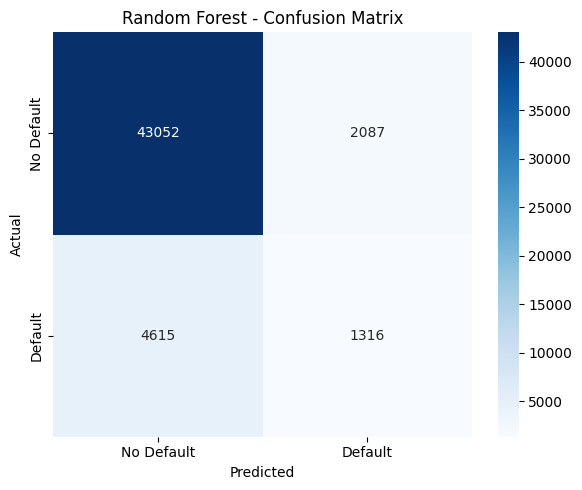

In [43]:
# Plot the confusion matrix for Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# **45. XGBoost with SMOTE**

In [44]:
# Train XGBoost on the SMOTE-balanced data
from xgboost import XGBClassifier
xgb_model = XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=42, eval_metric='logloss', n_jobs=-1)
xgb_model.fit(X_train_smote, y_train_smote)

y_pred_xgb = xgb_model.predict(X_test_processed)
y_prob_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)
xgb_roc_auc = roc_auc_score(y_test, y_prob_xgb)

print("XGBoost Performance")
print("--------------------")
print(f"Accuracy : {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall   : {xgb_recall:.4f}")
print(f"F1-Score : {xgb_f1:.4f}")
print(f"ROC-AUC  : {xgb_roc_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

XGBoost Performance
--------------------
Accuracy : 0.8863
Precision: 0.5863
Recall   : 0.0722
F1-Score : 0.1285
ROC-AUC  : 0.7532

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.99      0.94     45139
           1       0.59      0.07      0.13      5931

    accuracy                           0.89     51070
   macro avg       0.74      0.53      0.53     51070
weighted avg       0.86      0.89      0.85     51070



# **46. XGBoost - Confusion Matrix**

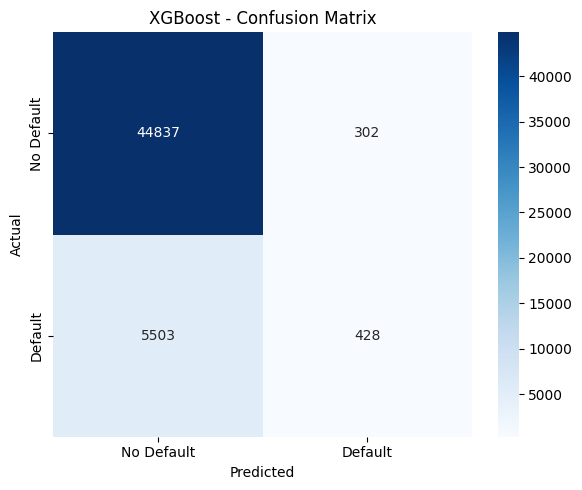

In [45]:
# Plot the confusion matrix for XGBoost
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
plt.title('XGBoost - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# **47. LightGBM with SMOTE**

In [46]:
# Train LightGBM on the SMOTE-balanced data
from lightgbm import LGBMClassifier
lgbm_model = LGBMClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=42, n_jobs=-1, verbose=-1)
lgbm_model.fit(X_train_smote, y_train_smote)

y_pred_lgbm = lgbm_model.predict(X_test_processed)
y_prob_lgbm = lgbm_model.predict_proba(X_test_processed)[:, 1]

lgbm_accuracy = accuracy_score(y_test, y_pred_lgbm)
lgbm_precision = precision_score(y_test, y_pred_lgbm)
lgbm_recall = recall_score(y_test, y_pred_lgbm)
lgbm_f1 = f1_score(y_test, y_pred_lgbm)
lgbm_roc_auc = roc_auc_score(y_test, y_prob_lgbm)

print("LightGBM Performance")
print("---------------------")
print(f"Accuracy : {lgbm_accuracy:.4f}")
print(f"Precision: {lgbm_precision:.4f}")
print(f"Recall   : {lgbm_recall:.4f}")
print(f"F1-Score : {lgbm_f1:.4f}")
print(f"ROC-AUC  : {lgbm_roc_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lgbm))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM Performance
---------------------
Accuracy : 0.8861
Precision: 0.5786
Recall   : 0.0701
F1-Score : 0.1251
ROC-AUC  : 0.7544

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.99      0.94     45139
           1       0.58      0.07      0.13      5931

    accuracy                           0.89     51070
   macro avg       0.73      0.53      0.53     51070
weighted avg       0.85      0.89      0.84     51070



# **48. LightGBM - Confusion Matrix**

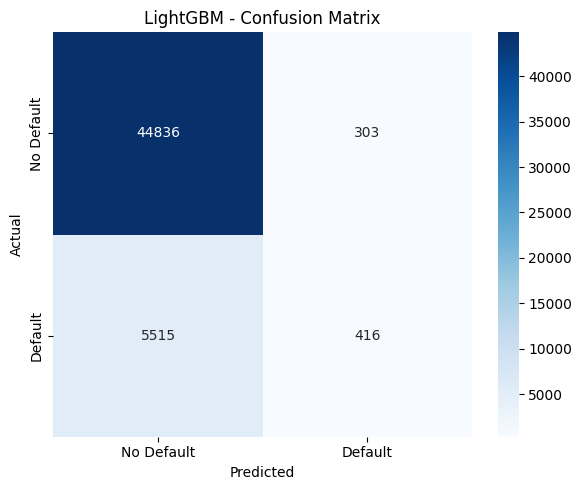

In [47]:
# Plot the confusion matrix for LightGBM
cm_lgbm = confusion_matrix(y_test, y_pred_lgbm)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_lgbm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
plt.title('LightGBM - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# **49. Prepare a Faster Tuning Subsample**

In [48]:
# Draw a balanced subsample of the SMOTE training data so cross-validation and tuning run in minutes rather than hours
tuning_sample_size = min(60000, X_train_smote.shape[0])
rng = np.random.RandomState(42)
tuning_idx = rng.choice(X_train_smote.shape[0], size=tuning_sample_size, replace=False)
X_tune = X_train_smote[tuning_idx]
y_tune = y_train_smote.iloc[tuning_idx].reset_index(drop=True)
print("Tuning subsample shape:", X_tune.shape)
print(y_tune.value_counts(normalize=True).mul(100).round(2))

Tuning subsample shape: (60000, 32)
Default
0    50.11
1    49.89
Name: proportion, dtype: float64


# **50. Stratified Cross-Validation**

In [49]:
# Run stratified 5-fold cross-validation on the tuning subsample (n_jobs=-1 on the outer loop only, n_jobs=1 on each model to avoid CPU oversubscription)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=20, random_state=42, n_jobs=1),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=42, eval_metric='logloss', n_jobs=1),
    'LightGBM': LGBMClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=42, n_jobs=1, verbose=-1)
}
cv_results = []
for name, model in cv_models.items():
    scores = cross_validate(model, X_tune, y_tune, cv=cv, scoring=['roc_auc', 'f1'], n_jobs=-1)
    cv_results.append([name, scores['test_roc_auc'].mean(), scores['test_roc_auc'].std(), scores['test_f1'].mean(), scores['test_f1'].std()])
cv_results = pd.DataFrame(cv_results, columns=['Model', 'Mean ROC-AUC', 'Std ROC-AUC', 'Mean F1', 'Std F1'])
display(cv_results.round(4))

,Model,Mean ROC-AUC,Std ROC-AUC,Mean F1,Std F1
0,Logistic Regression,0.7665,0.0021,0.6976,0.0028
1,Decision Tree,0.7577,0.0044,0.7587,0.0043
2,Random Forest,0.9569,0.0017,0.8926,0.0026
3,XGBoost,0.9635,0.0020,0.9261,0.0023
4,LightGBM,0.9634,0.0020,0.9253,0.0025


# **51. Hyperparameter Tuning - Random Forest**

In [50]:
# Tune Random Forest on the subsample using RandomizedSearchCV (n_jobs=-1 on the search only)
rf_param_grid = {
    'n_estimators': [100, 150, 200],
    'max_depth': [10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
rf_search = RandomizedSearchCV(RandomForestClassifier(random_state=42, n_jobs=1), rf_param_grid, n_iter=8, scoring='roc_auc', cv=3, random_state=42, n_jobs=-1)
rf_search.fit(X_tune, y_tune)
print("Best Random Forest Parameters:", rf_search.best_params_)
print("Best Cross-Validated ROC-AUC:", rf_search.best_score_)

Best Random Forest Parameters: {'n_estimators': 150, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 20}
Best Cross-Validated ROC-AUC: 0.9535399679180082


# **52. Hyperparameter Tuning - XGBoost**

In [51]:
# Tune XGBoost on the subsample using RandomizedSearchCV
xgb_param_grid = {
    'n_estimators': [200, 300, 400],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0]
}
xgb_search = RandomizedSearchCV(XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=1), xgb_param_grid, n_iter=8, scoring='roc_auc', cv=3, random_state=42, n_jobs=-1)
xgb_search.fit(X_tune, y_tune)
print("Best XGBoost Parameters:", xgb_search.best_params_)
print("Best Cross-Validated ROC-AUC:", xgb_search.best_score_)

Best XGBoost Parameters: {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 8, 'learning_rate': 0.1}
Best Cross-Validated ROC-AUC: 0.9635912893295632


# **53. Hyperparameter Tuning - LightGBM**

In [52]:
# Tune LightGBM on the subsample using RandomizedSearchCV
lgbm_param_grid = {
    'n_estimators': [200, 300, 400],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1],
    'num_leaves': [31, 50, 70]
}
lgbm_search = RandomizedSearchCV(LGBMClassifier(random_state=42, n_jobs=1, verbose=-1), lgbm_param_grid, n_iter=8, scoring='roc_auc', cv=3, random_state=42, n_jobs=-1)
lgbm_search.fit(X_tune, y_tune)
print("Best LightGBM Parameters:", lgbm_search.best_params_)
print("Best Cross-Validated ROC-AUC:", lgbm_search.best_score_)

Best LightGBM Parameters: {'num_leaves': 31, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.05}
Best Cross-Validated ROC-AUC: 0.9641450755277781


# **54. Refit Tuned Models on the Full Training Data**

In [53]:
# Refit each winning parameter set on the full SMOTE training data (one fit per model, not repeated across folds)
random_forest_tuned = RandomForestClassifier(**rf_search.best_params_, random_state=42, n_jobs=-1).fit(X_train_smote, y_train_smote)
xgb_model_tuned = XGBClassifier(**xgb_search.best_params_, random_state=42, eval_metric='logloss', n_jobs=-1).fit(X_train_smote, y_train_smote)
lgbm_model_tuned = LGBMClassifier(**lgbm_search.best_params_, random_state=42, n_jobs=-1, verbose=-1).fit(X_train_smote, y_train_smote)
print("Tuned models refit on the full training set.")

Tuned models refit on the full training set.


# **55. Evaluate the Tuned Models**

In [54]:
# Evaluate the tuned models on the held-out test set
tuned_models = {'Random Forest (Tuned)': random_forest_tuned, 'XGBoost (Tuned)': xgb_model_tuned, 'LightGBM (Tuned)': lgbm_model_tuned}
tuned_results = []
tuned_probs = {}
for name, model in tuned_models.items():
    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]
    tuned_probs[name] = y_prob
    tuned_results.append([name, accuracy_score(y_test, y_pred), precision_score(y_test, y_pred), recall_score(y_test, y_pred), f1_score(y_test, y_pred), roc_auc_score(y_test, y_prob)])
tuned_results = pd.DataFrame(tuned_results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'])
display(tuned_results.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest (Tuned),0.8688,0.3867,0.2219,0.2820,0.7450
1,XGBoost (Tuned),0.8858,0.5577,0.0791,0.1385,0.7502
2,LightGBM (Tuned),0.8864,0.5726,0.0845,0.1472,0.7544


# **56. Full Model Comparison Table**

In [55]:
# Build the full comparison table across all models
full_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Logistic Regression (SMOTE)', 'Decision Tree (SMOTE)', 'Random Forest (SMOTE)', 'XGBoost (SMOTE)', 'LightGBM (SMOTE)'],
    'Accuracy': [lr_accuracy, dt_accuracy, lr_smote_accuracy, dt_smote_accuracy, rf_accuracy, xgb_accuracy, lgbm_accuracy],
    'Precision': [lr_precision, dt_precision, lr_smote_precision, dt_smote_precision, rf_precision, xgb_precision, lgbm_precision],
    'Recall': [lr_recall, dt_recall, lr_smote_recall, dt_smote_recall, rf_recall, xgb_recall, lgbm_recall],
    'F1-Score': [lr_f1, dt_f1, lr_smote_f1, dt_smote_f1, rf_f1, xgb_f1, lgbm_f1],
    'ROC-AUC': [lr_roc_auc, dt_roc_auc, lr_smote_roc_auc, dt_smote_roc_auc, rf_roc_auc, xgb_roc_auc, lgbm_roc_auc]
})
full_results = pd.concat([full_results, tuned_results], ignore_index=True)
display(full_results.round(4).sort_values('ROC-AUC', ascending=False))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8869,0.6146,0.0696,0.1251,0.7617
2,Logistic Regression (SMOTE),0.6929,0.2289,0.6941,0.3443,0.7615
9,LightGBM (Tuned),0.8864,0.5726,0.0845,0.1472,0.7544
6,LightGBM (SMOTE),0.8861,0.5786,0.0701,0.1251,0.7544
5,XGBoost (SMOTE),0.8863,0.5863,0.0722,0.1285,0.7532
8,XGBoost (Tuned),0.8858,0.5577,0.0791,0.1385,0.7502
7,Random Forest (Tuned),0.8688,0.3867,0.2219,0.2820,0.7450
4,Random Forest (SMOTE),0.8688,0.3867,0.2219,0.2820,0.7450
3,Decision Tree (SMOTE),0.7802,0.1908,0.2753,0.2254,0.5610
1,Decision Tree,0.8017,0.1979,0.2318,0.2135,0.5542


# **57. Precision-Recall Curve Comparison**

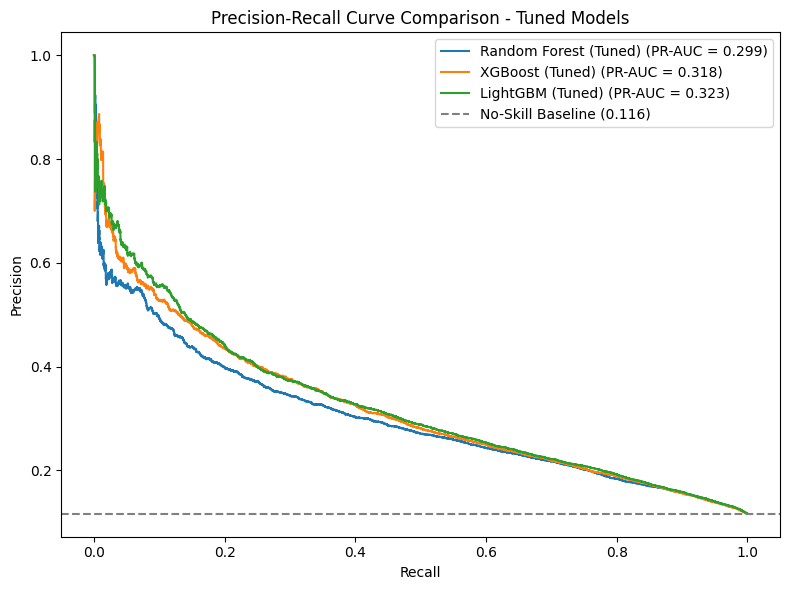

In [56]:
# Plot Precision-Recall curves for the tuned models
plt.figure(figsize=(8, 6))
for name, y_prob in tuned_probs.items():
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = auc(recall, precision)
    plt.plot(recall, precision, label=f'{name} (PR-AUC = {pr_auc:.3f})')
baseline_rate = y_test.mean()
plt.axhline(baseline_rate, linestyle='--', color='gray', label=f'No-Skill Baseline ({baseline_rate:.3f})')
plt.title('Precision-Recall Curve Comparison - Tuned Models')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.tight_layout()
plt.show()

# **58. SHAP Explainability**

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


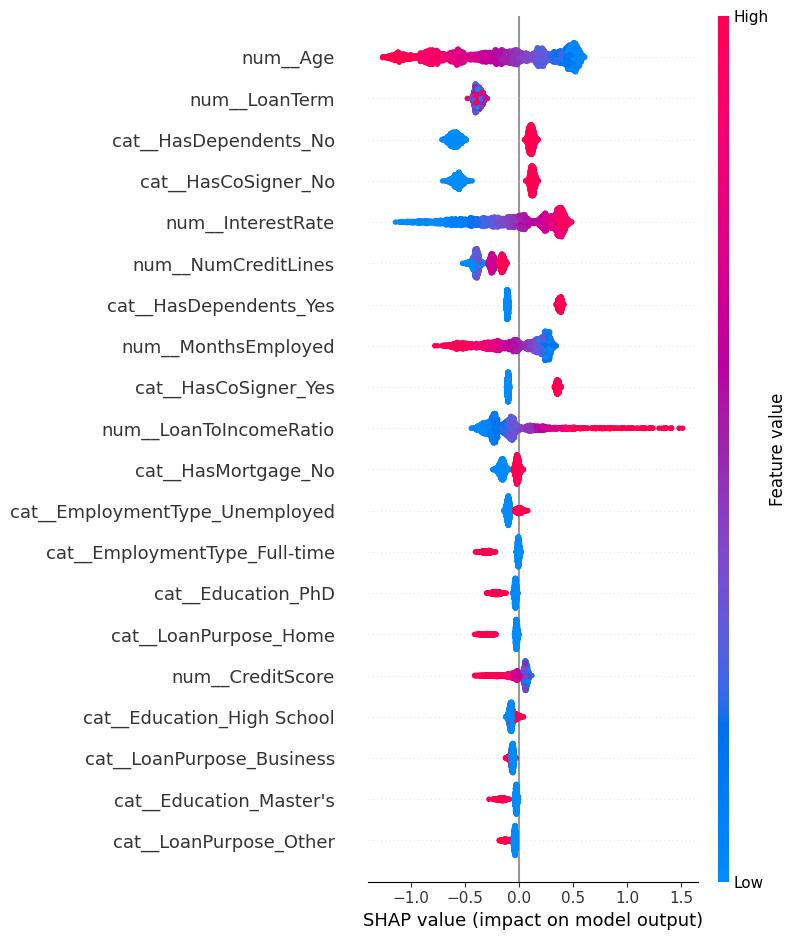

In [57]:
# Explain the best-performing tuned model using SHAP
import shap
feature_names = preprocessor.get_feature_names_out()
best_tuned_name = tuned_results.sort_values('ROC-AUC', ascending=False).iloc[0]['Model']
best_model = tuned_models[best_tuned_name]

sample_idx = np.random.RandomState(42).choice(X_test_processed.shape[0], size=min(3000, X_test_processed.shape[0]), replace=False)
X_test_sample = X_test_processed[sample_idx]

explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test_sample)
if isinstance(shap_values, list):
    shap_values = shap_values[1]

shap.summary_plot(shap_values, X_test_sample, feature_names=feature_names)

# **59. SHAP Feature Importance Ranking**

In [58]:
# Rank features by mean absolute SHAP value
shap_importance = pd.DataFrame({
    'Feature': feature_names,
    'Mean |SHAP Value|': np.abs(shap_values).mean(axis=0)
}).sort_values('Mean |SHAP Value|', ascending=False)
display(shap_importance.head(15))

,Feature,Mean |SHAP Value|
0,num__Age,0.454195
7,num__LoanTerm,0.380622
23,cat__HasDependents_No,0.357869
30,cat__HasCoSigner_No,0.342369
6,num__InterestRate,0.328061
5,num__NumCreditLines,0.304536
24,cat__HasDependents_Yes,0.245700
4,num__MonthsEmployed,0.236322
31,cat__HasCoSigner_Yes,0.226748
9,num__LoanToIncomeRatio,0.225877


# **60. Results Interpretation and Recommendations for Banks**

This section should be completed once the cells above have been run on the full dataset, using the
actual numbers produced in your output. Structure it around your research questions:

- **RQ1 (key attributes):** Report the top features from the SHAP ranking above (e.g. Age, Interest Rate,
  Credit Score, DTI Ratio, Loan-to-Income Ratio are typically strong signals in this kind of dataset).
- **RQ2 (best model):** State which model tops the Full Model Comparison Table by ROC-AUC/PR-AUC, and note
  the precision/recall trade-off it makes — with only ~11.6% defaulters, a model with high recall on the
  default class will usually cost some precision, and vice versa.
- **RQ3 (reducing NPAs):** Explain how a bank could use the model's predicted default probability as a risk
  score at the point of loan approval, rather than a hard accept/reject rule.
- **RQ4/RQ5 (MSME lending and future risk):** Translate the top SHAP features into practical lending
  guidance (e.g. tightening thresholds for high DTI or short employment history), while noting the
  limitation that this dataset is not MSME-specific.